In [1]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import chi2
from torch.distributions import MultivariateNormal

df_w = pd.read_csv("Wholesale customers data.csv")   # ajuste o caminho
F = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']
X_w   = torch.tensor(df_w[F].values, dtype=torch.float64)
canal = df_w['Channel']

In [8]:
Xc    = X_w - X_w.mean(dim=0)
S_inv = torch.linalg.inv(torch.cov(Xc.T))
d2    = torch.einsum('ij,jk,ik->i', Xc, S_inv, Xc)
mask  = d2 <= chi2.ppf(0.975, df=6)

X_lim     = X_w[mask]
canal_lim = canal[mask.numpy()].values          
X_lim_pad = (X_lim - X_lim.mean(dim=0)) / X_lim.std(dim=0)

print(X_lim.shape, "|", (~mask).sum().item(), )

torch.Size([409, 6]) | 31


In [3]:
K = 2
g = torch.Generator().manual_seed(0)
centros = X_lim_pad[torch.randperm(X_lim_pad.shape[0], generator=g)[:K]].clone()

for _ in range(50):
    rotulos = torch.cdist(X_lim_pad, centros).argmin(dim=1)
    for k in range(K):
        if (rotulos == k).sum() > 0:
            centros[k] = X_lim_pad[rotulos == k].mean(dim=0)

print(pd.crosstab(rotulos.numpy(), canal_lim))

col_0    1   2
row_0         
0      272  40
1       10  87


In [ ]:
from torch.distributions import MultivariateNormal

K = 2
N, D = X_lim_pad.shape

def em(X, K, iters=100, seed=0):
    g = torch.Generator().manual_seed(seed)
    N, D = X.shape
    pesos  = torch.ones(K, dtype=torch.float64) / K
    medias = X[torch.randperm(N, generator=g)[:K]].clone()
    covs   = torch.stack([torch.eye(D, dtype=torch.float64) for _ in range(K)])

    for _ in range(iters):
        # E-step
        logp   = torch.stack([MultivariateNormal(medias[k], covs[k]).log_prob(X)
                              for k in range(K)], dim=1)
        lognum = logp + torch.log(pesos)
        resp   = torch.softmax(lognum, dim=1)
        ll     = torch.logsumexp(lognum, dim=1).sum()

        # M-step
        Nk     = resp.sum(dim=0)
        pesos  = Nk / N
        medias = (resp.T @ X) / Nk[:, None]
        covs   = torch.stack([
            ((resp[:, k:k+1] * (X - medias[k])).T @ (X - medias[k])) / Nk[k]
            + 1e-6 * torch.eye(D, dtype=torch.float64)
            for k in range(K)])
    return resp, medias, covs, pesos, ll


melhor = None
for s in range(10):
    out = em(X_lim_pad, K, seed=s)
    if melhor is None or out[4] > melhor[4]:
        melhor = out

resp, medias, covs, pesos, ll = melhor
rotulos_gmm = resp.argmax(dim=1)

print("log-verossimilhança:", round(ll.item(), 2))
print("pesos:", pesos.numpy().round(3))
print(pd.crosstab(rotulos_gmm.numpy(), canal_lim))

log-verossimilhança: -2277.59
pesos: [0.501 0.499]
col_0    1    2
row_0          
0      202    6
1       80  121


In [5]:
print("=== K-means vs Channel ===");  print(pd.crosstab(rotulos.numpy(), canal_lim))
print("\n=== GMM vs Channel ===");    print(pd.crosstab(rotulos_gmm.numpy(), canal_lim))
print("\n=== K-means vs GMM ===");    print(pd.crosstab(rotulos.numpy(), rotulos_gmm.numpy()))
print("\npesos GMM:", pesos.numpy().round(3))
print("ambíguos (<0.6):", (resp.max(dim=1).values < 0.6).sum().item())
print("\ncentros GMM:"); print(pd.DataFrame(medias.numpy().round(2), columns=F))

=== K-means vs Channel ===
col_0    1   2
row_0         
0      272  40
1       10  87

=== GMM vs Channel ===
col_0    1    2
row_0          
0      202    6
1       80  121

=== K-means vs GMM ===
col_0    0    1
row_0          
0      208  104
1        0   97

pesos GMM: [0.501 0.499]
ambíguos (<0.6): 6

centros GMM:
   Fresh  Milk  Grocery  Frozen  Detergents_Paper  Delicassen
0   0.21 -0.61    -0.63    0.32             -0.62       -0.28
1  -0.21  0.61     0.63   -0.32              0.62        0.28


In [7]:
cl_km   = pd.Series(rotulos.numpy(),     name="K-means")
cl_gmm  = pd.Series(rotulos_gmm.numpy(), name="GMM")
canal_n = pd.Series(canal_lim, name="Canal").map({1: "Horeca", 2: "Retail"})

print(pd.crosstab(cl_km,  canal_n))
print(pd.crosstab(cl_gmm, canal_n))
print(pd.crosstab(cl_km,  cl_gmm))

Canal    Horeca  Retail
K-means                
0           272      40
1            10      87
Canal  Horeca  Retail
GMM                  
0         202       6
1          80     121
GMM        0    1
K-means          
0        208  104
1          0   97


horeca = hotel restaurante e cafe
retail = varejo

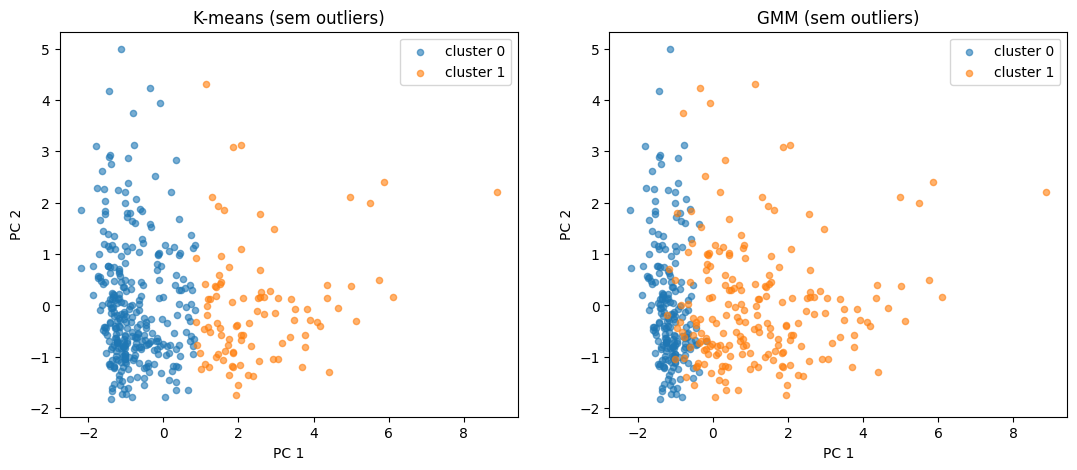

In [6]:
Xc2 = X_lim_pad - X_lim_pad.mean(dim=0)
U, S, Vt = torch.linalg.svd(Xc2, full_matrices=False)
Z = Xc2 @ Vt[:2].T

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for k in [0, 1]:
    ax1.scatter(Z[rotulos==k, 0], Z[rotulos==k, 1], s=20, alpha=.6, label=f"cluster {k}")
    ax2.scatter(Z[rotulos_gmm==k, 0], Z[rotulos_gmm==k, 1], s=20, alpha=.6, label=f"cluster {k}")
ax1.set_title("K-means (sem outliers)"); ax1.set_xlabel("PC 1"); ax1.set_ylabel("PC 2"); ax1.legend()
ax2.set_title("GMM (sem outliers)");     ax2.set_xlabel("PC 1"); ax2.set_ylabel("PC 2"); ax2.legend()
plt.show()